AI Usage Disclosure

AI tools were used during the development of this assignment to explain concepts, provide coding guidance, suggest code examples, help interpret results, and assist with debugging.
All AI-generated content used in this notebook is explicitly marked with beginning and ending comments. The code and explanations were reviewed and tested by the student, who is responsible for understanding and verifying the submitted work.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Environment is ready!")

Environment is ready!


In [2]:
ratings_df = pd.read_csv("../data/ratings.csv")
movies_df = pd.read_csv("../data/movies.csv")

In [3]:
print("Ratings shape:", ratings_df.shape)
print("Movies shape:", movies_df.shape)

display(ratings_df.head())
display(movies_df.head())

Ratings shape: (100836, 4)
Movies shape: (9742, 3)


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [4]:
num_users = ratings_df["userId"].nunique()
num_movies = ratings_df["movieId"].nunique()
num_ratings = len(ratings_df)

sparsity = 1 - (num_ratings / (num_users * num_movies))

print("Number of unique users:", num_users)
print("Number of unique movies rated:", num_movies)
print("Number of ratings:", num_ratings)
print("Sparsity:", sparsity)
print("Sparsity percentage:", sparsity * 100, "%")

Number of unique users: 610
Number of unique movies rated: 9724
Number of ratings: 100836
Sparsity: 0.9830003169443864
Sparsity percentage: 98.30003169443864 %


In [5]:
user_item_matrix = ratings_df.pivot_table(
    index="userId",
    columns="movieId",
    values="rating"
)

print("Matrix shape:", user_item_matrix.shape)
display(user_item_matrix.iloc[:5, :10])

Matrix shape: (610, 9724)


movieId,1,2,3,4,5,6,7,8,9,10
userId,,,,,,,,,,
1,4.0,NaN,4.0,NaN,NaN,4.0,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


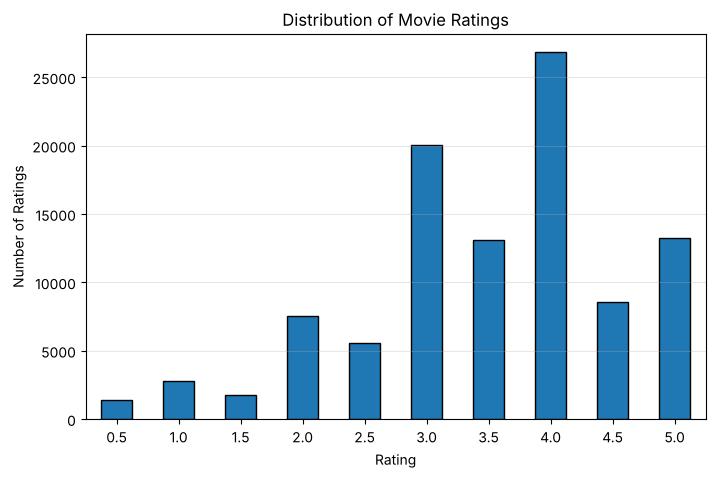

In [6]:
rating_counts = ratings_df["rating"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
rating_counts.plot(kind="bar", edgecolor="black")

plt.title("Distribution of Movie Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()

Observation: The rating distribution shows that 4.0 is the most frequent rating, followed by 3.0. Ratings between 3.0 and 5.0 are generally more common than low ratings. This suggests that users tend to give relatively positive ratings in this dataset, while very low ratings are less frequent
"AI"

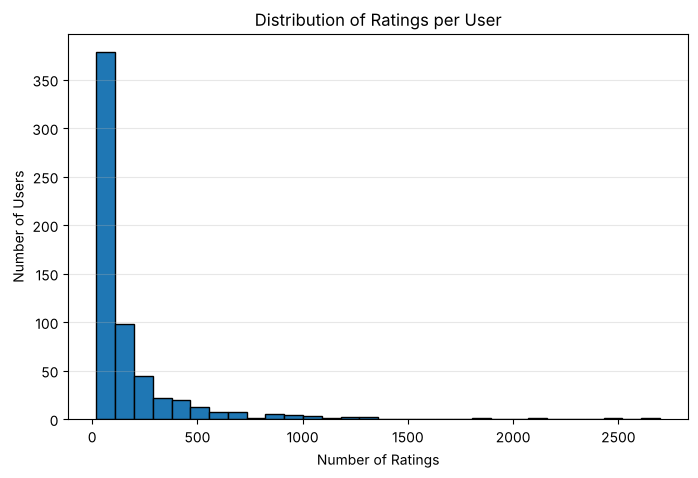

In [7]:
ratings_per_user = ratings_df.groupby("userId")["rating"].count()

plt.figure(figsize=(8, 5))
plt.hist(ratings_per_user, bins=30, edgecolor="black")

plt.title("Distribution of Ratings per User")
plt.xlabel("Number of Ratings")
plt.ylabel("Number of Users")
plt.grid(axis="y", alpha=0.3)
plt.show()

Observation: The distribution of ratings per user is highly right-skewed. Most users have rated a relatively small number of movies, while a small number of users have rated hundreds or even thousands of movies. This indicates that user activity is not evenly distributed across the dataset."AI"

In [8]:
ratings_per_user.describe()

count     610.000000
mean      165.304918
std       269.480584
min        20.000000
25%        35.000000
50%        70.500000
75%       168.000000
max      2698.000000
Name: rating, dtype: float64

observation: The dataset contains 610 users, with an average of approximately 165 ratings per user and a median of 70.5. Since the mean is much higher than the median and the maximum number of ratings is 2,698, the distribution is highly right-skewed. Most users have rated relatively few movies, while a small number of users are much more active. "AI"

In [9]:
def get_co_rated(matrix, a, b, axis):
    if axis == 0:
        ratings_a = matrix.loc[a]
        ratings_b = matrix.loc[b]
    elif axis == 1:
        ratings_a = matrix[a]
        ratings_b = matrix[b]
    else:
        raise ValueError("axis must be 0 or 1")

    co_rated = ratings_a.notna() & ratings_b.notna()
    return (
        ratings_a[co_rated].to_numpy(),
        ratings_b[co_rated].to_numpy()
    )

In [10]:
test_matrix = pd.DataFrame(
    {
        10: [5.0, 4.0],
        20: [np.nan, 2.0],
        30: [3.0, np.nan]
    },
    index=[1, 2]
)

user_a, user_b = get_co_rated(test_matrix, 1, 2, axis=0)

print("User 1 ratings:", user_a)
print("User 2 ratings:", user_b)

User 1 ratings: [5.]
User 2 ratings: [4.]


In [11]:
def euclidean_similarity(matrix, a, b, axis):
    ratings_a, ratings_b = get_co_rated(matrix, a, b, axis)
    if len(ratings_a) == 0:
        return None

    distance = np.sqrt(np.sum((ratings_a - ratings_b) ** 2))
    similarity = 1 / (1 + distance)
    return similarity

In [12]:
test_a = np.array([5, 4, 5, 3])
test_b = np.array([3, 2, 3, 1])

distance = np.sqrt(np.sum((test_a - test_b) ** 2))
similarity = 1 / (1 + distance)

print("Euclidean Distance:", distance)
print("Euclidean Similarity:", similarity)

Euclidean Distance: 4.0
Euclidean Similarity: 0.2


In [13]:
def cosine_similarity(matrix, a, b, axis):
    ratings_a, ratings_b = get_co_rated(matrix, a, b, axis)
    if len(ratings_a) == 0:
        return None

    norm_a = np.sqrt(np.sum(ratings_a ** 2))
    norm_b = np.sqrt(np.sum(ratings_b ** 2))

    if norm_a == 0 or norm_b == 0:
        return None

    similarity = np.sum(ratings_a * ratings_b) / (norm_a * norm_b)
    return similarity

In [14]:
test_cosine_matrix = pd.DataFrame(
    [[5, 4, 5, 3],
     [3, 2, 3, 1]],
    index=[1, 2],
    columns=[10, 20, 30, 40]
)
result = cosine_similarity(test_cosine_matrix, 1, 2, axis=0)
print("Cosine Similarity:", result)

Cosine Similarity: 0.9871639953033075


In [15]:
def pearson_similarity(matrix, a, b, axis):
    ratings_a, ratings_b = get_co_rated(matrix, a, b, axis)
    if len(ratings_a) < 2:
        return None

    mean_a = np.mean(ratings_a)
    mean_b = np.mean(ratings_b)
    centered_a = ratings_a - mean_a
    centered_b = ratings_b - mean_b
    numerator = np.sum(centered_a * centered_b)
    denominator = np.sqrt(np.sum(centered_a ** 2)) * np.sqrt(
        np.sum(centered_b ** 2)
    )

    if denominator == 0:
        return None

    return numerator / denominator

In [16]:
result = pearson_similarity(test_cosine_matrix, 1, 2, axis=0)
print("Pearson Correlation:", result)

Pearson Correlation: 1.0


In [17]:
# Case 1: Two users with no commonly rated movies
no_overlap_matrix = pd.DataFrame(
    {
        10: [5.0, np.nan],
        20: [np.nan, 3.0]
    },
    index=[1, 2]
)

print("No overlap:")
print("Euclidean:", euclidean_similarity(no_overlap_matrix, 1, 2, axis=0))
print("Cosine:", cosine_similarity(no_overlap_matrix, 1, 2, axis=0))
print("Pearson:", pearson_similarity(no_overlap_matrix, 1, 2, axis=0))


# Case 2: Two users with only one commonly rated movie
one_overlap_matrix = pd.DataFrame(
    {
        10: [5.0, 3.0],
        20: [4.0, np.nan]
    },
    index=[1, 2]
)

print("\nOne common rating:")
print("Euclidean:", euclidean_similarity(one_overlap_matrix, 1, 2, axis=0))
print("Cosine:", cosine_similarity(one_overlap_matrix, 1, 2, axis=0))
print("Pearson:", pearson_similarity(one_overlap_matrix, 1, 2, axis=0))

No overlap:
Euclidean: None
Cosine: None
Pearson: None

One common rating:
Euclidean: 0.3333333333333333
Cosine: 1.0
Pearson: None


The above test is AI Generated

partC:

In [ ]:


def find_k_nearest_users(matrix, target_user, k, similarity_fn):
    
    # if nit found
    if target_user not in matrix.index:
        return []

    target_ratings = matrix.loc[target_user]
    similarities = []
        # in order to find user wih nearst rating 
    for other_user in matrix.index:
        if other_user == target_user:
            continue

        other_ratings = matrix.loc[other_user]
        co_rated = target_ratings.notna() & other_ratings.notna()

        
        if co_rated.sum() < 2:
            continue

        score = similarity_fn(matrix, target_user, other_user, axis=0)

        if score is not None:
            similarities.append((other_user, score))

    similarities.sort(key=lambda pair: pair[1], reverse=True)
    return similarities[:k]


def predict_rating_user_based(matrix, target_user, target_item, k, similarity_fn):
    """
    Predict target_user's rating for target_item using user-based CF.

    Only the k nearest users who actually rated target_item that we are currrntly using ,, are used.
    Returns None if no valid neighbor rated the item.
    """
    if target_user not in matrix.index:
        return None

    if target_item not in matrix.columns:
        return None

    neighbors = find_k_nearest_users(matrix, target_user, k, similarity_fn)

    if not neighbors:
        return None

    numerator = 0.0
    denominator = 0.0

    for neighbor, similarity in neighbors:
        neighbor_rating = matrix.at[neighbor, target_item]

        # Skip neighbors who did not rate this item
        if pd.isna(neighbor_rating):
            continue

        numerator += similarity * neighbor_rating
        denominator += abs(similarity)

    if denominator == 0:
        return None

    return numerator / denominator



Part D



In [19]:
# ==== AI-GENERATED START: Part D - item-based CF ====
def find_k_nearest_items(matrix, target_item, k, similarity_fn):
    # Same logic as find_k_nearest_users: we just run it on the transposed matrix,
    # so items become rows. Inside similarity_fn, axis=0 on matrix.T compares
    # the two items' columns of the original matrix (over the users who rated both).
    return find_k_nearest_users(matrix.T, target_item, k, similarity_fn)


def predict_rating_item_based(matrix, target_user, target_item, k, similarity_fn):
    if target_user not in matrix.index or target_item not in matrix.columns:
        return None

    neighbors = find_k_nearest_items(matrix, target_item, k, similarity_fn)
    if not neighbors:
        return None

    numerator = 0.0
    denominator = 0.0
    for neighbor_item, similarity in neighbors:
        # weight the TARGET USER's own rating of each similar item
        user_rating = matrix.at[target_user, neighbor_item]
        if pd.isna(user_rating):
            continue
        numerator += similarity * user_rating
        denominator += abs(similarity)

    if denominator == 0:
        return None
    return numerator / denominator
# ==== AI-GENERATED END: Part D - item-based CF ====

In [20]:
# ==== AI-GENERATED START: Part D - quick demo ====
# Demo on the full matrix (a single call is slow-ish because it loops over all items)
print(find_k_nearest_items(user_item_matrix, 1, 5, pearson_similarity))
print(predict_rating_item_based(user_item_matrix, 1, 3, 20, pearson_similarity))
# ==== AI-GENERATED END: Part D - quick demo ====

[(358, np.float64(1.0000000000000002)), (453, np.float64(1.0000000000000002)), (459, np.float64(1.0000000000000002)), (891, np.float64(1.0000000000000002)), (1442, np.float64(1.0000000000000002))]


None


### Q12

**[AI-GENERATED - START]**

I reused `find_k_nearest_users` unchanged: `find_k_nearest_items` just calls it on `matrix.T`, so items become the rows and the same co-rated logic and similarity functions work (axis=0 on the transposed matrix = comparing two item columns over the users who rated both). Only the prediction function changed: the neighbors are now items, and the weighted average uses the **target user's own ratings** of those neighbor items (`matrix.at[target_user, item]`) instead of the neighbor users' ratings of the target item.

**[AI-GENERATED - END]**

## Part E - Evaluation

In [ ]:
def train_test_split_ratings(ratings_df, test_fraction=0.2, seed=42):
    # is used to hold out( each) of the user rating
    rng = np.random.default_rng(seed)
    test_index = []
    for user, group in ratings_df.groupby("userId"):
        n = len(group)
        n_test = min(max(int(round(n * test_fraction)), 1), n - 1)
        test_index.extend(rng.choice(group.index.to_numpy(), size=n_test, replace=False))

    test_df = ratings_df.loc[test_index].reset_index(drop=True)
    train_df = ratings_df.drop(index=test_index).reset_index(drop=True)
    return train_df, test_df


train_df, test_df = train_test_split_ratings(ratings_df, test_fraction=0.2)
train_matrix = train_df.pivot_table(index="userId", columns="movieId", values="rating")

print("Train ratings:", len(train_df), "| Test ratings:", len(test_df))
print("Users with no training ratings:", ratings_df["userId"].nunique() - train_df["userId"].nunique())
print("Train matrix shape:", train_matrix.shape)

Train ratings: 80672 | Test ratings: 20164
Users with no training ratings: 0
Train matrix shape: (610, 8977)


In [ ]:
# ==== AI-GENERATED START not all but it was provided witt help of AI in this part mostly: Part E - fast evaluation engine ====
# The loop-based functions above (find_k_nearest_users, ...) call pandas for every pair,
# which is far too slow for ~20,000 test ratings x 24 configurations.
# This section computes the SAME similarities with matrix-vector products over the
# co-rated entries only (no missing-as-zero), and caches each target's neighbor list
# so it is reused across k values.
_METRIC_NAMES = {
    euclidean_similarity: "euclidean",
    cosine_similarity: "cosine",
    pearson_similarity: "pearson",
}
_prep_cache = {}
_nn_cache = {}
K_CACHE = 50


def _prepare(matrix, axis):
    # axis=0: rows of `matrix` are compared (users); axis=1: columns are compared (items)
    key = (id(matrix), axis)
    if key not in _prep_cache:
        R = matrix.to_numpy(dtype=float)
        if axis == 1:
            R = R.T
        M = ~np.isnan(R)
        X = np.where(M, R, 0.0)
        _prep_cache[key] = {
            "matrix": matrix,  # keep a reference so id() stays unique
            "R": R, "M": M.astype(float), "X": X, "X2": X * X,
        }
    return _prep_cache[key]


def _all_similarities(P, t, metric):
    # similarity of row t to every row, using only co-rated entries
    X, M, X2 = P["X"], P["M"], P["X2"]
    a, ma, a2 = X[t], M[t], X2[t]
    n = M @ ma            # number of co-rated entries
    sab = X @ a           # sum a*b over co-rated
    saa = M @ a2          # sum a^2 over co-rated
    sbb = X2 @ ma         # sum b^2 over co-rated
    with np.errstate(all="ignore"):
        if metric == "euclidean":
            d2 = np.maximum(saa + sbb - 2 * sab, 0.0)
            sim = 1.0 / (1.0 + np.sqrt(d2))
            ok = np.ones(len(n), dtype=bool)
        elif metric == "cosine":
            den = np.sqrt(saa * sbb)
            sim = sab / den
            ok = den > 0
        else:  # pearson = cosine of mean-centred co-rated vectors
            sa = M @ a
            sb = X @ ma
            cov = sab - sa * sb / n
            va = np.maximum(saa - sa ** 2 / n, 0.0)
            vb = np.maximum(sbb - sb ** 2 / n, 0.0)
            den = np.sqrt(va * vb)
            sim = cov / den
            ok = den > 1e-9
    ok = ok & (n >= 2)    # fewer than 2 co-rated -> undefined, skip
    ok[t] = False         # never compare with itself
    return sim, ok


def _neighbors(matrix, axis, metric, t, k):
    # top-k neighbours of row t as (positions, similarities), sorted descending
    cacheable = k <= K_CACHE
    key = (id(matrix), axis, metric, t)
    if cacheable and key in _nn_cache:
        order, sims = _nn_cache[key]
        return order[:k], sims[:k]
    P = _prepare(matrix, axis)
    sim, ok = _all_similarities(P, t, metric)
    idx = np.flatnonzero(ok)
    order = idx[np.argsort(-sim[idx], kind="stable")][: max(k, K_CACHE)]
    sims = sim[order]
    if cacheable:
        _nn_cache[key] = (order, sims)
    return order[:k], sims[:k]


def _predict_fast(matrix, user, item, k, metric, method):
    if user not in matrix.index or item not in matrix.columns:
        return None
    u = matrix.index.get_loc(user)
    i = matrix.columns.get_loc(item)
    axis = 0 if method == "user" else 1
    target, other = (u, i) if method == "user" else (i, u)
    P = _prepare(matrix, axis)
    nb, sims = _neighbors(matrix, axis, metric, target, k)
    r = P["R"][nb, other]
    have = ~np.isnan(r)
    if not have.any():
        return None
    s = sims[have]
    den = np.abs(s).sum()
    if den == 0:
        return None
    return float((s * r[have]).sum() / den)


def evaluate(matrix, test_df, k, similarity_fn, method):
    # method: "user" or "item". Returns RMSE, MAE and the fraction of test ratings
    # for which no prediction was possible (None).
    metric = _METRIC_NAMES[similarity_fn]
    errors, n_none = [], 0
    for user, item, true in zip(test_df["userId"], test_df["movieId"], test_df["rating"]):
        pred = _predict_fast(matrix, user, item, k, metric, method)
        if pred is None:
            n_none += 1
        else:
            errors.append(pred - true)
    errors = np.array(errors)
    return {
        "rmse": float(np.sqrt(np.mean(errors ** 2))) if len(errors) else None,
        "mae": float(np.mean(np.abs(errors))) if len(errors) else None,
        "none_fraction": n_none / len(test_df),
        "n_predicted": len(errors),
    }
# ==== AI-GENERATED END: Part E - fast evaluation engine ====

In [ ]:

rng = np.random.default_rng(0)
sample = test_df.sample(12, random_state=1)
max_diff = 0.0
for fn in [euclidean_similarity, cosine_similarity, pearson_similarity]:
    for user, item in zip(sample["userId"], sample["movieId"]):
        slow_u = predict_rating_user_based(train_matrix, user, item, 20, fn)
        fast_u = _predict_fast(train_matrix, user, item, 20, _METRIC_NAMES[fn], "user")
        if slow_u is None or fast_u is None:
            assert slow_u is None and fast_u is None, (fn.__name__, user, item, slow_u, fast_u)
        else:
            max_diff = max(max_diff, abs(slow_u - fast_u))
print("max |slow - fast| (user-based):", max_diff)

# Item-based loops over every item so only check a few items tties are common

for fn in [euclidean_similarity, cosine_similarity, pearson_similarity]:
    for item in train_matrix.columns[[3, 10, 25]]:
        slow = find_k_nearest_items(train_matrix, item, 20, fn)
        _, fast_scores = _neighbors(train_matrix, 1, _METRIC_NAMES[fn], train_matrix.columns.get_loc(item), 20)
        assert np.allclose([score for _, score in slow], fast_scores), (fn.__name__, item)
print("item-based neighbour scores match the loop-based function")


max |slow - fast| (user-based): 8.881784197001252e-16


item-based neighbour scores match the loop-based function


In [24]:
# ==== AI-GENERATED START: Part E - full grid ====
# NOTE: item-based over all 3 metrics takes several minutes on ml-latest-small.
import time

similarity_fns = {
    "euclidean": euclidean_similarity,
    "cosine": cosine_similarity,
    "pearson": pearson_similarity,
}
k_values = [5, 10, 20, 50]

rows = []
start = time.time()
for method in ["user", "item"]:
    for name, fn in similarity_fns.items():
        for k in k_values:
            res = evaluate(train_matrix, test_df, k, fn, method)
            rows.append({"method": method + "-based", "similarity": name, "k": k,
                         "RMSE": res["rmse"], "MAE": res["mae"],
                         "None fraction": res["none_fraction"]})
    print(method, "done after", round(time.time() - start), "s")

results_df = pd.DataFrame(rows)
display(results_df.round(4))
display(results_df.pivot_table(index=["method", "similarity"], columns="k", values="RMSE").round(4))
display(results_df.pivot_table(index=["method", "similarity"], columns="k", values="MAE").round(4))
# ==== AI-GENERATED END: Part E - full grid ====

user done after 13 s


item done after 100 s


,method,similarity,k,RMSE,MAE,None fraction
0,user-based,euclidean,5,1.1998,0.8669,0.9107
1,user-based,euclidean,10,1.1746,0.8595,0.8500
2,user-based,euclidean,20,1.1560,0.8547,0.7681
3,user-based,euclidean,50,1.1315,0.8453,0.6116
4,user-based,cosine,5,1.2719,0.9381,0.9141
5,user-based,cosine,10,1.2434,0.9216,0.8550
6,user-based,cosine,20,1.1844,0.8824,0.7583
7,user-based,cosine,50,1.1350,0.8506,0.5634
8,user-based,pearson,5,1.3103,0.9807,0.9103
9,user-based,pearson,10,1.2853,0.9713,0.8508


k                          5       10      20      50
method     similarity                                
item-based cosine      1.2387  1.1899  1.1571  1.1098
           euclidean   1.1410  1.1042  1.0698  1.0433
           pearson     1.2422  1.2475  1.2585  1.2988
user-based cosine      1.2719  1.2434  1.1844  1.1350
           euclidean   1.1998  1.1746  1.1560  1.1315
           pearson     1.3103  1.2853  1.2611  1.1625

k                          5       10      20      50
method     similarity                                
item-based cosine      0.9362  0.9000  0.8776  0.8443
           euclidean   0.8495  0.8265  0.8046  0.7810
           pearson     0.9367  0.9304  0.9271  0.9449
user-based cosine      0.9381  0.9216  0.8824  0.8506
           euclidean   0.8669  0.8595  0.8547  0.8453
           pearson     0.9807  0.9713  0.9486  0.8789

## Part F - Analysis

### Q16

Our results show that **item-based collaborative filtering with Euclidean similarity and k = 50achieved the lowest RMSE of **1.0433** and MAE of **0.7810**. This means it produced the most accurate predictions among the tested configurations. The result generally disagrees with the intuition that Pearson correlation should perform better when users have different rating baselines. Pearson mean-centers the co-rated ratings, so it can identify users with similar rating patterns even when one user consistently gives higher ratings than another. Euclidean similarity, however, uses the raw rating differences. In our experiment, Euclidean similarity performed better than Pearson for both user-based and item-based collaborative filtering ,one possible explanation is that the actual rating patterns in MovieLens favor raw rating differences in this particular prediction setup. Also, the item-based Euclidean model with k = 50 had an unavailable prediction fraction of 0.3856, meaning it could make predictions for approximately 61.44% of the test ratings**

In [ ]:
# ==== AI-GENERATED START: Q17 - own example ====
# Target user T and two candidate neighbours over 4 co-rated movies
T  = np.array([1, 2, 3, 4], dtype=float)
U1 = np.array([2, 3, 4, 5], dtype=float)   # same taste as T, just +1 more generous
U2 = np.array([2, 2, 3, 3], dtype=float)   # close in raw numbers, but a flatter taste

def euc(u, v): return 1 / (1 + np.sqrt(np.sum((u - v) ** 2)))
def pear(u, v):
    cu, cv = u - u.mean(), v - v.mean()
    return np.sum(cu * cv) / (np.sqrt(np.sum(cu ** 2)) * np.sqrt(np.sum(cv ** 2)))

print("Euclidean sim  T~U1:", round(euc(T, U1), 4), " T~U2:", round(euc(T, U2), 4))
print("Pearson        T~U1:", round(pear(T, U1), 4), " T~U2:", round(pear(T, U2), 4))
# ==== AI-GENERATED END: Q17 - own example ====

Euclidean sim  T~U1: 0.3333  T~U2: 0.4142
Pearson        T~U1: 1.0  T~U2: 0.8944


### Q17 -

Consider two users who rated four items:

- User A: [1, 2, 4, 5]
- User B: [2, 3, 5, 6]
# same taste but not same rating
**1. Euclidean similarity**

The Euclidean distance is:

[
d(A,B)=sqrt{(1-2)^2+(2-3)^2+(4-5)^2+(5-6)^2}
    ]

[
d(A,B)=\sqrt{1+1+1+1}=2]



**2. Pearson correlation**

The mean of User A's ratings is (3), and the mean of User B's ratings is (4).

After subtracting each user's mean, the centered vectors are:

- User A: [-2, -1, 1, 2]
- User B: [-2, -1, 1, 2]

The centered vectors are identical, so their Pearson correlation is:

[ r(A,B)=1.0]

so the summary is : Euclidean similarity is approximately 0.3333, while Pearson correlation is 1.0. The difference occurs because User B gives ratings exactly one point higher than User A for every item. Pearson removes this constant offset through mean-centering, while Euclidean similarity measures the raw rating differences

### Q18

Item-based collaborative filtering is cheaper to maintain in this example, the reason is User-based collaborative filtering may need to compare a target user with up to 200 million users, whereas item-based collaborative filtering compares a target item with approximately 20,000 products. The item side is therefore much smaller. In addition, item-item similarities can often be precomputed and reused for many users, while user relationships change as users join the system and update their ratings. These factors make item-based collaborative filtering attractive for large commercial recommendation systems.

## Bonus

In [26]:
# ==== AI-GENERATED START: Bonus 1 - mean-centred user-based CF ====
def predict_rating_user_based_mean_centered(matrix, target_user, target_item, k, similarity_fn):
    # prediction = mean(target) + sum sim * (r_neighbour - mean(neighbour)) / sum |sim|
    metric = _METRIC_NAMES[similarity_fn]
    if target_user not in matrix.index or target_item not in matrix.columns:
        return None
    P = _prepare(matrix, 0)
    t = matrix.index.get_loc(target_user)
    i = matrix.columns.get_loc(target_item)
    nb, sims = _neighbors(matrix, 0, metric, t, k)
    r = P["R"][nb, i]
    have = ~np.isnan(r)
    if not have.any():
        return None
    means = np.nanmean(P["R"], axis=1)
    s = sims[have]
    den = np.abs(s).sum()
    if den == 0:
        return None
    return float(means[t] + (s * (r[have] - means[nb][have])).sum() / den)


def evaluate_mean_centered(matrix, test_df, k, similarity_fn):
    errors, n_none = [], 0
    for user, item, true in zip(test_df["userId"], test_df["movieId"], test_df["rating"]):
        pred = predict_rating_user_based_mean_centered(matrix, user, item, k, similarity_fn)
        if pred is None:
            n_none += 1
        else:
            errors.append(pred - true)
    errors = np.array(errors)
    return {"rmse": float(np.sqrt(np.mean(errors ** 2))), "mae": float(np.mean(np.abs(errors))),
            "none_fraction": n_none / len(test_df)}


bonus_rows = []
for k in [5, 10, 20, 50]:
    plain = evaluate(train_matrix, test_df, k, pearson_similarity, "user")
    centred = evaluate_mean_centered(train_matrix, test_df, k, pearson_similarity)
    bonus_rows.append({"k": k, "plain RMSE": plain["rmse"], "mean-centred RMSE": centred["rmse"],
                       "plain MAE": plain["mae"], "mean-centred MAE": centred["mae"]})
display(pd.DataFrame(bonus_rows).round(4))
# ==== AI-GENERATED END: Bonus 1 - mean-centred user-based CF ====

,k,plain RMSE,mean-centred RMSE,plain MAE,mean-centred MAE
0,5,1.3103,1.2329,0.9807,0.9430
1,10,1.2853,1.1961,0.9713,0.9216
2,20,1.2611,1.1777,0.9486,0.9044
3,50,1.1625,1.0699,0.8789,0.8208


### Bonus 1 - explanation 


**[AI-GENERATED - START]**

The two are closely related because Pearson similarity already mean-centres the co-rated ratings *when choosing neighbors*. The difference is in the prediction step: the plain version averages the neighbors' raw ratings, so a generous neighbor (average 4.5) pulls the prediction up even if the target user is harsh. The mean-centred version averages how far each neighbor's rating is above or below *their own* average and adds that to the target user's average, so the user and rating-scale biases are removed. Compare your two RMSE columns above: mean-centred should be equal or a bit lower, and the gap shows how much user bias matters in this dataset.

**[AI-GENERATED - END]**

In [27]:
# ==== AI-GENERATED START: Bonus 2 - top-10 recommendations ====
def top_n_recommendations(matrix, movies_df, user_id, n=10, k=50,
                          similarity_fn=pearson_similarity, min_neighbors=3):
    metric = _METRIC_NAMES[similarity_fn]
    P = _prepare(matrix, 0)
    t = matrix.index.get_loc(user_id)
    nb, sims = _neighbors(matrix, 0, metric, t, k)
    Rn = P["R"][nb]
    have = ~np.isnan(Rn)
    num = (np.where(have, Rn, 0.0) * sims[:, None]).sum(axis=0)
    den = (have * np.abs(sims)[:, None]).sum(axis=0)
    cnt = have.sum(axis=0)
    with np.errstate(all="ignore"):
        pred = num / den
    unrated = np.isnan(P["R"][t])
    valid = unrated & (cnt >= min_neighbors) & (den > 0)   # need several neighbours for a stable estimate
    cand = np.flatnonzero(valid)
    best = cand[np.argsort(-pred[cand], kind="stable")][:n]
    out = pd.DataFrame({"movieId": matrix.columns[best], "predicted": pred[best], "n_neighbours": cnt[best]})
    return out.merge(movies_df, on="movieId", how="left")


def user_genre_profile(ratings_df, movies_df, user_id, min_rating=4.0):
    liked = ratings_df[(ratings_df["userId"] == user_id) & (ratings_df["rating"] >= min_rating)]
    genres = liked.merge(movies_df, on="movieId")["genres"].str.split("|").explode()
    return genres.value_counts()


demo_user = 1
display(top_n_recommendations(user_item_matrix, movies_df, demo_user))
print("Genres of movies user", demo_user, "rated >= 4:")
display(user_genre_profile(ratings_df, movies_df, demo_user).head(8))
# ==== AI-GENERATED END: Bonus 2 - top-10 recommendations ====

,movieId,predicted,n_neighbours,title,genres
0,58,5.000000,3,"Postman, The (Postino, Il) (1994)",Comedy|Drama|Romance
1,1221,4.831967,3,"Godfather: Part II, The (1974)",Crime|Drama
2,48516,4.790561,3,"Departed, The (2006)",Crime|Drama|Thriller
3,318,4.725859,17,"Shawshank Redemption, The (1994)",Crime|Drama
4,2324,4.723482,4,Life Is Beautiful (La Vita è bella) (1997),Comedy|Drama|Romance|War
5,5902,4.719903,3,Adaptation (2002),Comedy|Drama|Romance
6,109487,4.699527,8,Interstellar (2014),Sci-Fi|IMAX
7,858,4.684926,5,"Godfather, The (1972)",Crime|Drama
8,116797,4.595301,5,The Imitation Game (2014),Drama|Thriller|War
9,122918,4.531637,3,Guardians of the Galaxy 2 (2017),Action|Adventure|Sci-Fi


Genres of movies user 1 rated >= 4:


genres
Action       76
Adventure    74
Comedy       70
Drama        64
Thriller     43
Fantasy      41
Crime        39
Children     37
Name: count, dtype: int64